In [45]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.covariance import MinCovDet


def sklearn_cov(X):
    mcd = MinCovDet().fit(X)
    n_flagged = (~mcd.support_).sum()
    print(f"{n_flagged} / {len(mcd.support_)} samples flagged as outliers")
    cov = mcd.covariance_        # shape (n_freq, n_freq), robust to RFI outliers
    off_diag = cov - np.diag(np.diag(cov))
    p = cov.shape[0]
    mean_off_diag = np.abs(off_diag).sum() / (p * (p - 1))   # divide by count of off-diagonal entries
    mean_diag = np.abs(np.diag(cov)).mean()
    ratio = mean_off_diag / mean_diag
    plt.imshow(cov)
    print(ratio)
    
def np_cov(X):
    cov = np.cov(X.T)   # noise_data shape (n_freq, n_time); np.cov treats rows as variables by default,
                            # so no transpose needed here (unlike sklearn's (n_samples, n_features) convention)

    off_diag = cov - np.diag(np.diag(cov))
    p = cov.shape[0]
    mean_off_diag = np.abs(off_diag).sum() / (p * (p - 1))
    mean_diag = np.abs(np.diag(cov)).mean()
    ratio = mean_off_diag / mean_diag
    print(ratio)

# Baseband data

In [5]:
data = np.load('event_22154974_BB.npz')
power, freq, time = data['power'], data['freq'], data['time']
freq = freq[::-1]
power = power[::-1, :]

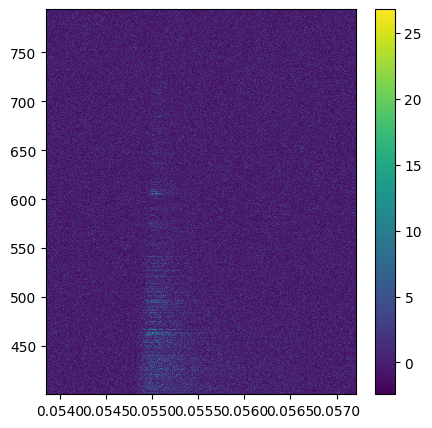

In [9]:
fig = plt.figure(figsize=(5, 5))
img = plt.imshow(power,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

Noise segments we will draw from


Text(0, 0.5, 'Frequency [MHz]')

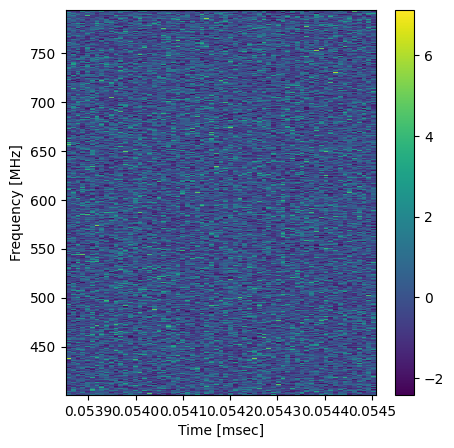

In [40]:
time_array = np.asarray(time, dtype=np.float32)[None, :]
data_reshaped = power
freq_array_reshaped = np.asarray(freq, dtype=np.float32)[:, None]
times_noise = np.asarray(time_array[0][0:int(len(time_array[0])/5)])
noise_data = data_reshaped[:,0:len(times_noise)]
print("Noise segments we will draw from")
fig = plt.figure(figsize=(5, 5))
img = plt.imshow(noise_data,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(times_noise[0], times_noise[-1], freq[0], freq[-1]))
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

### frequency covariance

In [ ]:
print("SKLearn covariance")
sklearn_cov(noise_data.T)
print("Numpy covariance")
np_cov(noise_data.T)

SKLearn covariance


/opt/pysetup/.venv/lib/python3.11/site-packages/sklearn/covariance/_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-25764.469110038229701 > -25766.820103167916386). You may want to try with a higher value of support_fraction (current value: 1.000).
  warnings.warn(


## time covariance

SKLearn covariance
237 / 820 samples flagged as outliers
0.03529958934110017
Numpy covariance
0.027840249068952827


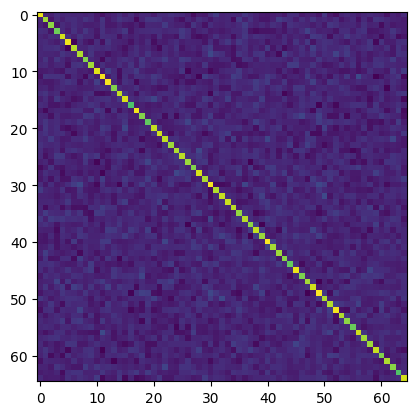

In [46]:
print("SKLearn covariance")
sklearn_cov(noise_data)
print("Numpy covariance")
np_cov(noise_data)